# **Классификация качества игровых рецензий Metacritic (PC)**

**Датасет:** [Metacritic PC Games Reviews](https://www.kaggle.com/datasets/beridzeg45/metacritic-pc-games-reviews)

**Тип задачи:** бинарная классификация

**Основной метод:** k ближайших соседей (kNN), для сравнения — логистическая регрессия, случайный лес.


# 1. Описание задачи

Датасет содержит рецензии на PC-игры с сайта Metacritic: каждая строка — это **одна рецензия** (критика или обычного пользователя) на **одну игру**. Одна игра представлена множеством строк.

**Признаки:**
- `Game Title` — название игры
- `Game Poster` — ссылка на обложку (информации не несёт)
- `Game Release Date` — дата выхода игры (формат вида `3-Nov-17`)
- `Game Developer` — разработчик
- `Genre` — жанр(ы) игры
- `Platforms` — платформы
- `Product Rating` — возрастной рейтинг (E, T, M, ...)
- `Overall Metascore` — мета-оценка игры (0–100)
- `Overall User Rating` — пользовательская оценка игры (0–10, бывает `'tbd'`)
- `Reviewer Name` — имя рецензента
- `Reviewer Type` — тип рецензента: `'Critic'` или `'User'`
- `Rating Given By The Reviewer` — оценка, данная в конкретной рецензии (критики: 0–100, пользователи: 0–10)
- `Review Date` — дата рецензии
- `Review Text` — текст рецензии

**Целевая переменная:** target = 1, если оценка рецензии высокая (≥ 75 из 100 — «Generally Favorable» по шкале Metacritic), и 0 иначе.

**Что нужно предсказать:** по характеристикам игры и типу рецензента — поставит ли конкретная рецензия высокую оценку.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

# 2. Читаем данные
Смотрим на размер таблицы, типы столбцов и число непустых значений

In [ ]:
df = pd.read_csv('metacritic_pc_games.csv', low_memory=False)
print("Размер датасета (строк, столбцов):", df.shape)
df.head(10)

Размер датасета (строк, столбцов): (513250, 14)


,Game Title,Game Poster,Game Release Date,Game Developer,Genre,Platforms,Product Rating,Overall Metascore,Overall User Rating,Reviewer Name,Reviewer Type,Rating Given By The Reviewer,Review Date,Review Text
0,.hackG.U. Last Recode,https://static.metacritic.com/images/products/...,3-Nov-17,CyberConnect2,"Genre(s):Miscellaneous,Compilation","PlayStation4,Switch,PC",T,69.0,8.1,ZTGD,Critic,85.0,NaN,The release of .hack//G.U. Last Recode is a ...
1,.hackG.U. Last Recode,https://static.metacritic.com/images/products/...,3-Nov-17,CyberConnect2,"Genre(s):Miscellaneous,Compilation","PlayStation4,Switch,PC",T,69.0,8.1,RPGamer,Critic,80.0,NaN,.hack//G.U. has remained one of my all-time ...
2,.hackG.U. Last Recode,https://static.metacritic.com/images/products/...,3-Nov-17,CyberConnect2,"Genre(s):Miscellaneous,Compilation","PlayStation4,Switch,PC",T,69.0,8.1,COGconnected,Critic,75.0,NaN,Last Recode turned out to be something that ...
3,.hackG.U. Last Recode,https://static.metacritic.com/images/products/...,3-Nov-17,CyberConnect2,"Genre(s):Miscellaneous,Compilation","PlayStation4,Switch,PC",T,69.0,8.1,Worth Playing,Critic,70.0,NaN,.hack//G.U. Last Recode is really for the fa...
4,.hackG.U. Last Recode,https://static.metacritic.com/images/products/...,3-Nov-17,CyberConnect2,"Genre(s):Miscellaneous,Compilation","PlayStation4,Switch,PC",T,69.0,8.1,CGMagazine,Critic,70.0,NaN,.hack//G.U. Last Recode is a fascinating nov...
5,.hackG.U. Last Recode,https://static.metacritic.com/images/products/...,3-Nov-17,CyberConnect2,"Genre(s):Miscellaneous,Compilation","PlayStation4,Switch,PC",T,69.0,8.1,Hardcore Gamer,Critic,60.0,NaN,.hack//G.U. was a flawed but ultimately ente...
6,.hackG.U. Last Recode,https://static.metacritic.com/images/products/...,3-Nov-17,CyberConnect2,"Genre(s):Miscellaneous,Compilation","PlayStation4,Switch,PC",T,69.0,8.1,Destructoid,Critic,55.0,NaN,hack//G.U. Last Recode's intended audience i...
7,007_ NightFire,https://static.metacritic.com/images/products/...,28-Nov-02,Gearbox Software,"Genre(s):Action,Shooter,Shooter,First-Person,M...",PC,T,59.0,6.1,GameZone,Critic,89.0,NaN,"Not only is the game fun, the movie sequence..."
8,007_ NightFire,https://static.metacritic.com/images/products/...,28-Nov-02,Gearbox Software,"Genre(s):Action,Shooter,Shooter,First-Person,M...",PC,T,59.0,6.1,Maxim Online,Critic,80.0,NaN,Stealing the best gadgets and characters fro...
9,007_ NightFire,https://static.metacritic.com/images/products/...,28-Nov-02,Gearbox Software,"Genre(s):Action,Shooter,Shooter,First-Person,M...",PC,T,59.0,6.1,PC Gameworld,Critic,80.0,NaN,"Though Nightfire does have its problems, it ..."


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 513250 entries, 0 to 513249
Data columns (total 14 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Game Title                    513196 non-null  object 
 1   Game Poster                   513196 non-null  object 
 2   Game Release Date             513196 non-null  object 
 3   Game Developer                512977 non-null  object 
 4   Genre                         513196 non-null  object 
 5   Platforms                     513250 non-null  object 
 6   Product Rating                425527 non-null  object 
 7   Overall Metascore             513181 non-null  float64
 8   Overall User Rating           513128 non-null  object 
 9   Reviewer Name                 512347 non-null  object 
 10  Reviewer Type                 513250 non-null  object 
 11  Rating Given By The Reviewer  510449 non-null  float64
 12  Review Date                   405044 non-nul

**Что видно из `info()`:**
- в таблице одна строка на рецензию; у 2 801 строки (около 0,5%) нет оценки рецензента (`Rating Given By The Reviewer`: 510 449 непустых из 513 250) — для них целевая переменная не определена;
- `Overall User Rating` имеет тип `object`, а не число — в нём есть текстовые значения (`'tbd'`);
- `Review Date` заполнен у 405 044 строк из 513 250, то есть пропущен примерно у 21%;
- `Product Rating` пропущен у 87 723 строк (около 17%);.

# 3. Создаем целевую переменную и готовим признаки

**Единица наблюдения** — рецензия.

1. **Единая шкала оценок.** Критики ставят оценки по шкале 0–100, пользователи - 0–10. Чтобы сравнивать с единым порогом, оценки пользователей умножаем на 10. Перед этим печатаем минимум и максимум по каждому типу рецензентов - проверяем, что шкалы действительно такие, как мы думаем.
2. **Удаляем строки без оценки.** Если оценки рецензента нет (`NaN`), мы не знаем истинный класс. Нельзя оставлять такие строки: выражение `NaN >= 75` дает `False`, и они молча превратились бы в класс 0, искажая и обучение, и метрики.
3. **Строим `target`:** 1, если оценка ≥ 75.
4. **Чистим `Overall User Rating`:** текстовое `'tbd'` («to be determined») превращаем в `NaN`.
5. **Разбираем даты** и считаем два числовых признака: год выхода игры и «лаг» рецензии (сколько дней прошло от релиза до рецензии).
6. **Жанр:** значения вида `Genre(s):Action,Adventure` сводим к основному (первому) жанру.

In [ ]:
df['Rating'] = pd.to_numeric(df['Rating Given By The Reviewer'], errors='coerce')

print('Шкалы оценок до пересчёта:')
print(df.groupby('Reviewer Type')['Rating'].agg(['min', 'max', 'count']))

is_user = df['Reviewer Type'].eq('User')
df.loc[is_user, 'Rating'] = df.loc[is_user, 'Rating'] * 10

n_before = len(df)
df = df.dropna(subset=['Rating', 'Game Title']).copy()
print(f'\nУдалено строк без оценки или без названия игры: {n_before - len(df)}, осталось {len(df)}')

df['target'] = (df['Rating'] >= 75).astype(int)

df['Overall User Rating'] = pd.to_numeric(df['Overall User Rating'], errors='coerce')

Шкалы оценок до пересчёта:
               min    max   count
Reviewer Type                    
Critic         0.0  100.0  105405
User           0.0   10.0  405044

Удалено строк без оценки или без названия игры: 2853, осталось 510397


In [ ]:
rel = pd.to_datetime(df['Game Release Date'], format='%d-%b-%y', errors='coerce')
rev = pd.to_datetime(df['Review Date'],       format='%d-%b-%y', errors='coerce')

print('Дата релиза:   распознано', rel.notna().sum(), 'из', df['Game Release Date'].notna().sum(), 'непустых')
print('Дата рецензии: распознано', rev.notna().sum(), 'из', df['Review Date'].notna().sum(), 'непустых')
print('Лаг будет известен у', int((rev.notna() & rel.notna()).sum()), 'строк из', len(df))
print('Рецензии с датой по типу рецензента:')
print(df.assign(has_date=rev.notna()).groupby('Reviewer Type')['has_date'].mean().round(3))

df['Release Year']      = rel.dt.year
df['Review Lag (days)'] = (rev - rel).dt.days

df['Genre'] = df['Genre'].str.replace('Genre(s):', '', regex=False).str.split(',').str[0].str.strip()

print('\nБаланс классов в целом по датасету:')
print(df['target'].value_counts())

Дата релиза:   распознано 510397 из 510397 непустых
Дата рецензии: распознано 405017 из 405017 непустых
Лаг известен у 405017 строк из 510397


**Какие столбцы исключаем из признаков и почему:**
- `Rating Given By The Reviewer` и служебный `Rating` — из них построен `target` (**утечка**);
- `Game Poster`, `Reviewer Name`, `Review Text` — уникальные или текстовые значения, не подходят для kNN;
- `Game Developer` — около 2,7 тыс. уникальных значений
- исходные `Game Release Date`, `Review Date` — заменены числовыми `Release Year` и `Review Lag (days)`;
- `Game Title` **не является признаком**, но мы оставляем его как идентификатор группы, чтобы разбить выборки по играм.

In [ ]:
drop_cols = ['Game Poster', 'Game Release Date', 'Review Date', 'Reviewer Name',
             'Review Text', 'Rating Given By The Reviewer', 'Rating', 'Game Developer']
df = df.drop(columns=drop_cols).reset_index(drop=True)
df.head()

,Game Title,Genre,Platforms,Product Rating,Overall Metascore,Overall User Rating,Reviewer Type,target,Release Year,Review Lag (days)
0,.hackG.U. Last Recode,"Genre(s):Miscellaneous,Compilation","PlayStation4,Switch,PC",T,69.0,8.1,Critic,1,2017,NaN
1,.hackG.U. Last Recode,"Genre(s):Miscellaneous,Compilation","PlayStation4,Switch,PC",T,69.0,8.1,Critic,1,2017,NaN
2,.hackG.U. Last Recode,"Genre(s):Miscellaneous,Compilation","PlayStation4,Switch,PC",T,69.0,8.1,Critic,1,2017,NaN
3,.hackG.U. Last Recode,"Genre(s):Miscellaneous,Compilation","PlayStation4,Switch,PC",T,69.0,8.1,Critic,0,2017,NaN
4,.hackG.U. Last Recode,"Genre(s):Miscellaneous,Compilation","PlayStation4,Switch,PC",T,69.0,8.1,Critic,0,2017,NaN


# 4. Разбиваем данные на обучающую и тестовую выборки

Делим выборку примерно в соотношении **80% / 20%**, с двумя условиями:

- **По играм (группам).** Все рецензии одной игры попадают в одну выборку. Иначе тест содержал бы игры, уже «знакомые» модели по train.
- **Со стратификацией по целевому классу** - чтобы доля высоких оценок в train и test была примерно одинаковой.

Для этого используем `StratifiedGroupKFold`: делим данные на 5 частей по играм с сохранением баланса классов и берем одну часть как тест (≈ 20%).

**Важно: разбиваем до очистки и заполнения пропусков.**

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

num_features = ['Overall Metascore', 'Overall User Rating', 'Release Year', 'Review Lag (days)']
cat_features = ['Reviewer Type', 'Product Rating', 'Genre', 'Platforms']

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(df, df['target'], groups=df['Game Title']))

df_train = df.iloc[train_idx].copy()
df_test  = df.iloc[test_idx].copy()

print('Строк в train:', len(df_train), '| в test:', len(df_test))
print('Игр в train:', df_train['Game Title'].nunique(), '| в test:', df_test['Game Title'].nunique())
print('Общих игр в train и test (должно быть 0):',
      len(set(df_train['Game Title']) & set(df_test['Game Title'])))
print('Доля target=1: train =', round(df_train['target'].mean(), 3),
      '| test =', round(df_test['target'].mean(), 3))

Строк в train: 418545 | в test: 91852
Игр в train: 4380 | в test: 1059
Общих игр в train и test (должно быть 0): 0
Доля target=1: train = 0.535 | test = 0.575


# 5. Визуализируем данные и вычисляем основные характеристики

Смотрим статистики, распределения и корреляции.

In [ ]:
df_train[num_features + ['target']].describe().T

,count,mean,std,min,25%,50%,75%,max
Overall Metascore,418545.0,78.019009,12.004337,16.0,72.0,81.0,86.0,97.0
Overall User Rating,416729.0,6.489771,2.231686,0.3,5.7,7.1,8.1,9.2
Release Year,418545.0,2014.165719,5.853597,1995.0,2011.0,2014.0,2020.0,2023.0
Review Lag (days),333815.0,763.401714,1429.179912,-4171.0,6.0,65.0,807.0,10187.0
target,418545.0,0.534760,0.498791,0.0,0.0,1.0,1.0,1.0


In [ ]:
df_train[cat_features].describe().T

,count,unique,top,freq
Reviewer Type,418545,2,User,333815
Product Rating,351841,7,M,204375
Genre,418545,1119,"Genre(s):Action,Shooter,Shooter,First-Person,S...",22308
Platforms,418545,206,PC,123363


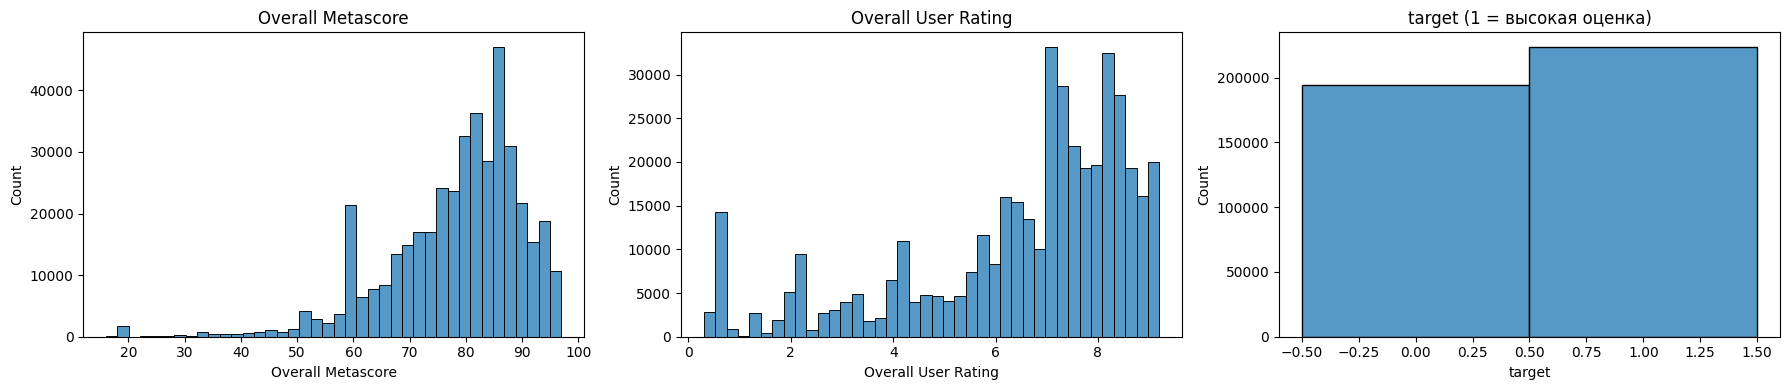

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(df_train['Overall Metascore'], bins=40, ax=axes[0]).set_title('Overall Metascore')
sns.histplot(df_train['Overall User Rating'], bins=40, ax=axes[1]).set_title('Overall User Rating')
sns.histplot(df_train['target'], discrete=True, ax=axes[2]).set_title('target (1 = высокая оценка)')
plt.tight_layout(); plt.show()

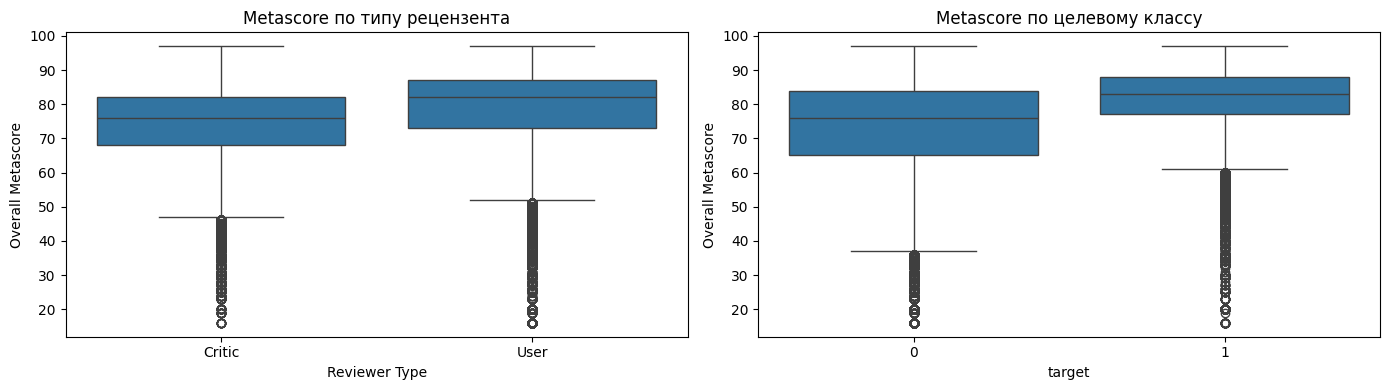

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df_train, x='Reviewer Type', y='Overall Metascore', ax=axes[0]).set_title('Metascore по типу рецензента')
sns.boxplot(data=df_train, x='target', y='Overall Metascore', ax=axes[1]).set_title('Metascore по целевому классу')
plt.tight_layout(); plt.show()

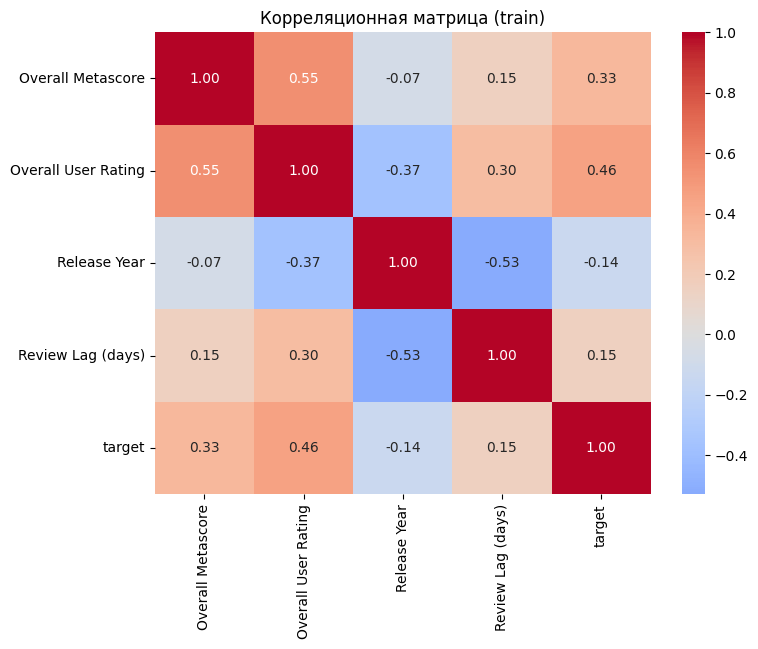

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_train[num_features + ['target']].corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Корреляционная матрица (train)'); plt.show()

In [ ]:
display(df_train.groupby('target')[num_features].mean())

display(df_train.groupby('Reviewer Type')['target'].mean().rename('доля target=1'))

,Overall Metascore,Overall User Rating,Release Year,Review Lag (days)
target,,,,
0,73.803697,5.398974,2015.016536,541.823160
1,81.686325,7.435391,2013.425510,968.599098


,доля target=1
Reviewer Type,
Critic,0.596093
User,0.519192


- `Overall Metascore` — оценка игры, а `target` — оценка *рецензии*. Корреляция должна быть заметной.
- Если на правой диаграмме медиана Metascore заметно выше у класса 1 — признак информативен для классификации.
- Таблица средних показывает то же в числах: чем больше разница между строками `target = 0` и `target = 1`, тем полезнее признак.
- Различие долей `target = 1` у критиков и пользователей показывает, что `Reviewer Type` тоже несёт информацию (у этих групп разные привычки в оценках).
- Корреляция между `Overall Metascore` и `Overall User Rating` обычно умеренная: игры, любимые критиками, нравятся и пользователям, но не всегда.

# 6. Разбираемся с выбросами

Оценки по построению лежат в диапазоне 0–100 (Metascore) и 0–10 (User Rating), поэтому сначала убеждаемся, что «физически невозможных» значений нет. Затем проверяем лаг рецензии: рецензия, написанная до релиза игры (отрицательный лаг), либо через 10+ лет после — подозрительна (ошибка в датах).

Порядок действий. Правило удаления «по строке» (лаг < 0 или > 10 лет) не использует статистики данных, поэтому утечки не создаёт. Применяем его одинаково к train и test.

Строки, где лаг неизвестен (`NaN`, нет даты рецензии), не удаляем: их обработаем в `Pipeline`.

In [ ]:
print('Metascore вне [0,100]:   ', ((df_train['Overall Metascore'] < 0) | (df_train['Overall Metascore'] > 100)).sum())
print('User Rating вне [0,10]:  ', ((df_train['Overall User Rating'] < 0) | (df_train['Overall User Rating'] > 10)).sum())
print('Отрицательный лаг:       ', (df_train['Review Lag (days)'] < 0).sum())
print('Лаг больше 10 лет:       ', (df_train['Review Lag (days)'] > 365 * 10).sum())
print()
df_train['Review Lag (days)'].describe()

Metascore вне [0,100]:    0
User Rating вне [0,10]:   0
Отрицательный лаг:        2565
Лаг больше 10 лет:        20592



,Review Lag (days)
count,333815.000000
mean,763.401714
std,1429.179912
min,-4171.000000
25%,6.000000
50%,65.000000
75%,807.000000
max,10187.000000


In [ ]:
def bad_lag(d):
    return (d['Review Lag (days)'] < 0) | (d['Review Lag (days)'] > 365 * 10)

n_tr, n_te = len(df_train), len(df_test)
df_train = df_train[~bad_lag(df_train)]
df_test  = df_test[~bad_lag(df_test)]
print(f'Удалено аномальных лагов: train {n_tr - len(df_train)}, test {n_te - len(df_test)}')

Удалено аномальных лагов: train 23157, test 6216


# 7. Пропущенные значения

Смотрим долю пропусков в каждом признаке (по train).

**Стратегия разная для разных признаков:**

| Признак | Доля пропусков | Решение |
|---|---|---|
| `Overall Metascore`, `Overall User Rating`, `Genre`, `Platforms`, `Reviewer Type`, `Release Year` | малая | **удаляем строки** — потеря данных незначительна |
| `Product Rating` | заметная (около 20%) | **не удаляем**, заменяем отдельной категорией `'unknown'` в `Pipeline` |
| `Review Lag (days)` | большая (нет даты рецензии) | **не удаляем**, заполняем медианой и добавляем индикатор «был пропуск» в `Pipeline` |

In [ ]:
missing = (df_train[num_features + cat_features].isnull().mean() * 100).round(2)
missing.sort_values(ascending=False).rename('% пропусков в train')

,% пропусков в train
Review Lag (days),21.43
Product Rating,16.63
Overall User Rating,0.46
Overall Metascore,0.00
Release Year,0.00
Reviewer Type,0.00
Genre,0.00
Platforms,0.00


In [ ]:
core_cols = ['Overall Metascore', 'Overall User Rating', 'Genre', 'Platforms', 'Reviewer Type', 'Release Year']

n_tr, n_te = len(df_train), len(df_test)
df_train = df_train.dropna(subset=core_cols)
df_test  = df_test.dropna(subset=core_cols)
print(f'Удалено строк с пропусками: train {n_tr - len(df_train)} ({(n_tr - len(df_train))/n_tr:.2%}), '
      f'test {n_te - len(df_test)} ({(n_te - len(df_test))/n_te:.2%})')

X_train, y_train, groups_train = df_train[num_features + cat_features], df_train['target'], df_train['Game Title']
X_test,  y_test                = df_test[num_features + cat_features],  df_test['target']

print('\nИтоговые размеры: X_train', X_train.shape, '| X_test', X_test.shape)
print('Оставшиеся пропуски в X_train (их заполнит Pipeline):')
print(X_train.isnull().sum()[lambda s: s > 0])

Удалено строк с пропусками: train 1808 (0.46%), test 528 (0.62%)

Итоговые размеры: X_train (393580, 8) | X_test (85108, 8)
Оставшиеся пропуски в X_train (их заполнит Pipeline):
Review Lag (days)    83011
Product Rating       64801
dtype: int64


# 8. Обрабатываем категориальные признаки

Метод ближайших соседей работает только с числами, поэтому для каждой категории появляется столбец из 0 и 1.

Настройки кодировщика:
- `handle_unknown='infrequent_if_exist'` — категории, которых не было в train, не вызывают ошибку в test, а попадают в группу редких;
- `min_frequency=50` — редкие категории (менее 50 строк) объединяются в одну. У `Platforms` сотни уникальных комбинаций, и без объединения получилось бы много почти пустых столбцов;
- пропуски в категориях заменяем значением `'unknown'` (так сохраняем информацию о том, что рейтинг не указан).

Кодировщик обучается только на train — внутри `Pipeline`.

In [ ]:
for c in cat_features:
    print(f'{c}: {X_train[c].nunique()} категорий; самые частые:')
    print('   ', X_train[c].value_counts().head(5).to_dict())

Reviewer Type: 2 категорий; самые частые:
    {'User': 310569, 'Critic': 83011}
Product Rating: 7 категорий; самые частые:
    {'M': 192119, 'T': 99827, 'E10+': 20039, 'E': 16099, 'RP': 389}
Genre: 1088 категорий; самые частые:
    {'Genre(s):Action,Shooter,Shooter,First-Person,Sci-Fi,Sci-Fi,Arcade': 18419, 'Genre(s):Role-Playing,ActionRPG': 17198, 'Genre(s):ActionRPG,Role-Playing,ActionRPG': 17043, 'Genre(s):Strategy,Real-Time,General': 16283, 'Genre(s):Action,Shooter,First-Person,Arcade': 15571}
Platforms: 205 категорий; самые частые:
    {'PC': 111796, 'PlayStation3,Xbox360,PC': 48714, 'PlayStation4,XboxOne,PC': 35264, 'PlayStation4,PlayStation5,Stadia,XboxOne,XboxSeriesX,PC': 21672, 'PlayStation4,PlayStation5,XboxOne,XboxSeriesX,PC': 19671}


# 9. Нормализация и единый конвейер предобработки

**Нормализация здесь обязательна:** kNN — метрический метод, он считает расстояния между объектами. `Release Year` (~1995–2023) и `Review Lag` в днях (тысячи) имеют совершенно иной масштаб, чем Metascore (0–100) и User Rating (0–10), без стандартизации перевесили бы остальные признаки. Числовые признаки приводим к нулевому среднему и единичной дисперсии (`StandardScaler`). One-hot признаки из {0, 1} оставляем как есть.

**Единый `Pipeline`.** Все шаги (заполнение пропусков, масштабирование, кодирование, классификатор) собираем в один объект. Тогда медианы, среднее и стандартное отклонение, список категорий считаются только на обучающих данных и затем применяются к test без повторного обучения — утечки статистик из теста нет.

Чтобы не копировать код для каждой модели, оформляем сборку предобработки функцией `make_preprocessor`. Она каждый раз создаёт новый объект, поэтому модели не влияют друг на друга. Параметры:
- `scale` — масштабировать ли числа (kNN, логистической регрессии и наивному Байесу нужно; случайному лесу — нет);
- `dense` — вернуть плотную матрицу.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier

def make_preprocessor(num_cols=num_features, cat_cols=cat_features, scale=True, dense=False):
    num_steps = [('imputer', SimpleImputer(strategy='median', add_indicator=True))]
    if scale:
        num_steps.append(('scaler', StandardScaler()))
    num_pipe = Pipeline(num_steps)

    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='unknown')),
        ('encoder', OneHotEncoder(handle_unknown='infrequent_if_exist',
                                  min_frequency=50, sparse_output=not dense)),
    ])
    return ColumnTransformer([('num', num_pipe, num_cols), ('cat', cat_pipe, cat_cols)],
                             sparse_threshold=0 if dense else 0.3)

SUBSAMPLE = min(40000, len(X_train))
X_sub = X_train.sample(SUBSAMPLE, random_state=RANDOM_STATE)
y_sub = y_train.loc[X_sub.index]
g_sub = groups_train.loc[X_sub.index]

prep_check = make_preprocessor().fit(X_sub)
print('Объектов в подвыборке:', len(X_sub))
print('Признаков после предобработки:', prep_check.transform(X_sub).shape[1])

Объектов в подвыборке: 40000
Признаков после предобработки: 213


# 10. kNN: ошибки на обучающей и тестовой выборках, матрицы рассогласования, выбор k

**Метрики.** Для классификации используем:
- *accuracy* — доля верных ответов;
- *precision / recall / F1* из `classification_report` — по каждому классу отдельно;
- *матрицу рассогласования* — сколько объектов каждого класса модель угадала и в какой класс «ошиблась».

## 10.1. Первая модель с k = 5

In [ ]:
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, recall_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

baseline_acc = y_test.value_counts(normalize=True).max()
print(f'Baseline (всегда предсказывать самый частый класс): accuracy = {baseline_acc:.3f}\n')

knn_pipe = Pipeline([('prep', make_preprocessor()),
                     ('clf', KNeighborsClassifier(n_neighbors=5))])
knn_pipe.fit(X_sub, y_sub)

y_pred_train = knn_pipe.predict(X_sub)
y_pred_test  = knn_pipe.predict(X_test)

print(f'k = 5   accuracy на train: {accuracy_score(y_sub, y_pred_train):.3f}')
print(f'k = 5   accuracy на test:  {accuracy_score(y_test, y_pred_test):.3f}')
print('\nОтчёт на тестовой выборке:')
print(classification_report(y_test, y_pred_test, target_names=['низкая (0)', 'высокая (1)']))

Baseline (всегда предсказывать самый частый класс): accuracy = 0.569

k = 5   accuracy на train: 0.782
k = 5   accuracy на test:  0.645

Отчёт на тестовой выборке:
              precision    recall  f1-score   support

  низкая (0)       0.60      0.53      0.56     36670
 высокая (1)       0.67      0.73      0.70     48438

    accuracy                           0.64     85108
   macro avg       0.64      0.63      0.63     85108
weighted avg       0.64      0.64      0.64     85108



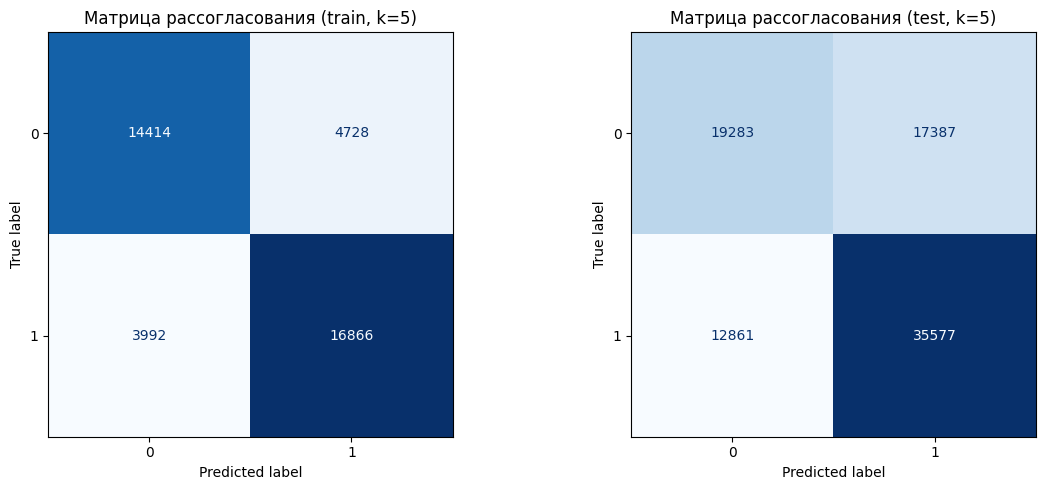

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_sub, y_pred_train, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Матрица рассогласования (train, k=5)')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('Матрица рассогласования (test, k=5)')
plt.tight_layout(); plt.show()

(Строки — истинный класс, столбцы — предсказание. На диагонали — верные ответы; вне диагонали — ошибки: «высокая оценка принята за низкую» и наоборот.)

accuracy на train у kNN завышена, потому что каждый обучающий объект при предсказании «видит» самого себя среди ближайших соседей.

## 10.2. Подбор числа соседей k по кросс-валидации

Если выбирать k по максимуму accuracy на тестовой выборке, то тест участвует в выборе модели и перестает быть честной оценкой (оптимистичная ошибка). k выбираем по кросс-валидации на обучающей выборке, а тест используем один раз — для финальной оценки уже выбранной модели.

Кросс-валидация здесь также идёт по играм (`StratifiedGroupKFold`): рецензии одной игры не попадают одновременно в обучающую и проверочную части.

In [ ]:
from sklearn.model_selection import cross_validate

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
ks = [3, 5, 7, 9, 11, 15, 21, 31]
cv_train, cv_val = [], []

for k in ks:
    model = Pipeline([('prep', make_preprocessor()),
                      ('clf', KNeighborsClassifier(n_neighbors=k))])
    scores = cross_validate(model, X_sub, y_sub, groups=g_sub, cv=cv,
                            scoring='accuracy', return_train_score=True, n_jobs=-1)
    cv_train.append(scores['train_score'].mean())
    cv_val.append(scores['test_score'].mean())

plt.figure(figsize=(8, 5))
plt.plot(ks, cv_train, 'o-', label='train accuracy (по фолдам)')
plt.plot(ks, cv_val,   's-', label='validation accuracy (по фолдам)')
plt.xlabel('k (число соседей)'); plt.ylabel('accuracy'); plt.legend(); plt.grid(alpha=.3)
plt.title('Выбор числа соседей k (кросс-валидация по играм)'); plt.show()

best_k = ks[int(np.argmax(cv_val))]
print(f'Оптимальное k = {best_k}, validation accuracy = {max(cv_val):.3f}')

- При малых k модель «подгоняется» под обучающие данные: train accuracy высокая, validation заметно ниже — переобучение.
- При росте k кривые сходятся, предсказание сглаживается. Слишком большое k даёт недообучение — модель становится слишком грубой.
- Оптимум — точка максимума validation accuracy; именно её мы берём как `best_k`.

## 10.3. Финальная модель и единственная оценка на тесте

In [ ]:
knn_best = Pipeline([('prep', make_preprocessor()),
                     ('clf', KNeighborsClassifier(n_neighbors=best_k))])
knn_best.fit(X_sub, y_sub)

y_pred_train = knn_best.predict(X_sub)
y_pred_test  = knn_best.predict(X_test)

knn_train_acc = accuracy_score(y_sub, y_pred_train)
knn_test_acc  = accuracy_score(y_test, y_pred_test)
print(f'k = {best_k}   accuracy на train: {knn_train_acc:.3f}')
print(f'k = {best_k}   accuracy на test:  {knn_test_acc:.3f}   (baseline: {baseline_acc:.3f})')
print('\nОтчёт на тестовой выборке:')
print(classification_report(y_test, y_pred_test, target_names=['низкая (0)', 'высокая (1)']))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_sub, y_pred_train, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Матрица рассогласования (train, k={best_k})')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title(f'Матрица рассогласования (test, k={best_k})')
plt.tight_layout(); plt.show()

# 11. Другие классификаторы

Сравниваем kNN с тремя классическими методами **на той же подвыборке** и с той же тестовой выборкой:
- **Логистическая регрессия** — линейный базовый классификатор, быстрый, требует масштабирования;
- **Случайный лес** — ансамбль деревьев, масштабирование не нужно, устойчив к выбросам;

Для каждой модели строим собственный `Pipeline` со своей предобработкой (с заполнением пропусков — иначе числовые признаки с `NaN` вызвали бы ошибку). Помимо accuracy считаем F1 по классу «высокая оценка» и ROC-AUC (качество ранжирования вероятностей, не зависит от порога).

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    f'kNN (k={best_k})': Pipeline([('prep', make_preprocessor()),
                                   ('clf', KNeighborsClassifier(n_neighbors=best_k))]),
    'LogisticRegression': Pipeline([('prep', make_preprocessor()),
                                    ('clf', LogisticRegression(max_iter=1000))]),
    'RandomForest': Pipeline([('prep', make_preprocessor(scale=False)),
                              ('clf', RandomForestClassifier(n_estimators=100, n_jobs=-1,
                                                             random_state=RANDOM_STATE))]),
}

results = []
for name, model in models.items():
    model.fit(X_sub, y_sub)
    pred_test = model.predict(X_test)
    results.append({
        'model': name,
        'train_acc': accuracy_score(y_sub, model.predict(X_sub)),
        'test_acc':  accuracy_score(y_test, pred_test),
        'test_f1 (класс 1)': f1_score(y_test, pred_test),
        'test_roc_auc': roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
    })
results_df = pd.DataFrame(results).sort_values('test_acc', ascending=False).reset_index(drop=True)
print(f'Baseline (самый частый класс): accuracy = {baseline_acc:.3f}')
results_df.round(3)

Большой разрыв между `train_acc` и `test_acc` — признак переобучения (у случайного леса он обычно самый заметный). Если `test_acc` модели близок к baseline, она почти ничего не извлекла из признаков. ROC-AUC удобен тем, что не зависит от порога 0.5: 0.5 — «угадывание», 1.0 — идеал.

# 12. Общие выводы

1. **Задача.** Решалась задача бинарной классификации: предсказать, будет ли оценка рецензии на PC-игру высокой (≥ 75 по шкале Metacritic), по характеристикам игры (мета- и пользовательский рейтинги, жанр, платформы, возрастной рейтинг, год выхода), времени написания рецензии и типу рецензента.
2. **Данные.** Шкалы критиков (0–100) и пользователей (0–10) приведены к единой; строки без оценки рецензента удалены (для них нет истинного класса); сырые даты преобразованы в год релиза и «лаг» рецензии.
3. **Утечки данных устранены.** Исключен столбец, из которого построен `target`; train/test и кросс-валидация делятся по играм, чтобы модель не «узнавала» игры из обучающей выборки; выбор k выполнен по кросс-валидации, а тест использован один раз для финальной оценки; все статистики предобработки считаются только по train.
4. **Качество данных.** Аномальные «лаги» рецензий (до релиза или более 10 лет) отброшены; пропуски в малых признаках удалены, а в `Product Rating` и `Review Lag` — заполнены внутри `Pipeline` (категория `'unknown'`, медиана + индикатор пропуска).
5. **Моделирование.** Категориальные признаки закодированы one-hot, числовые стандартизированы (для kNN это обязательно). Подбор k и сравнение моделей — в таблицах выше; итоговые числа этого запуска выводятся в ячейке ниже.
6. **Ограничения и развитие.** Текст рецензии не использовался, хотя это потенциально самый информативный признак (TF-IDF + логистическая регрессия). `Overall Metascore` и `Overall User Rating` частично включают саму оценку рецензии. Для kNN использована подвыборка из 40 000 строк. При необходимости можно настроить гиперпараметры остальных моделей и смотреть на F1 и ROC-AUC, а не только на accuracy.